<!-- d2l:prose id=word-embeddings-md-1 fw=all -->

# Word Embeddings

The language model of that section begins with a table that holds one
row of numbers for every token in its vocabulary. Gradient descent filled
that table along with everything else, and we never asked what its rows
mean. Here is a question we could have asked. *Physician* and *doctor* are
different tokens, and nothing in the training said that they are
interchangeable. Do their rows end up close anyway?

Before training there is no reason why they should. Looking up a row is
the same as multiplying the table by a *one-hot* vector, all zeros except
for a one at the word's index. One-hot vectors carry no similarity at all:
any two different words are orthogonal, and *doctor* is as far from
*physician* as from *banana*. Whatever similarity the rows hold, training
put there. In the 1950s the linguists Zellig Harris and J. R. Firth
[@Harris.1954; @Firth.1957] proposed where it could come from: words
that occur in similar contexts tend to mean similar things, or in Firth's
phrase, "you shall know a word by the company it keeps". Physicians and
doctors keep the same company. Both examine patients and write
prescriptions.

The question matters beyond word lists. Later in this chapter, whether
nearby vectors mean related things decides whether a search finds the
passage that answers a question, and word vectors are the smallest case
of that idea. This section asks which statistic of a text a learned word
vector records. It is a rare case in deep learning where we can write
down the answer and then check it. We train the skip-gram model of
word2vec
[@Mikolov.Chen.Corrado.ea.2013; @Mikolov.Sutskever.Chen.ea.2013], which
made word vectors cheap enough to learn from billions of words. We then
work out what its scores converge to [@Levy.Goldberg.2014] and check
the result on a toy corpus of four distinct words and on a slice of
Wikipedia. Two methods that compute vectors from the counts directly show
how much the choice of method matters, and human judgments of which words
are alike serve as the yardstick. The section ends with what no such
vector can do: give one word two meanings.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
import collections
import hashlib
import json
import os
import pandas as pd
import scipy.sparse.linalg
import time
import transformers
from safetensors import safe_open

<!-- d2l:prose id=word-embeddings-md-2 fw=all -->

The next three cells are setup, and a first reading can skip to
that section. They fix what every method shares, a
window of five words on each side and vectors of 100 dimensions, and name
the sources of the data. As in that section, results that
take long to compute are stored: here the 23 runs of
that section, which the environment variable
`D2L_RERUN=we-grid` repeats in about ten minutes on one GPU.

In [3]:
GPU = torch.cuda.is_available()
# A job given a GPU (CUDA_VISIBLE_DEVICES set) must not fall back to the CPU
assert GPU or not os.environ.get('CUDA_VISIBLE_DEVICES'), (
    'a GPU is assigned, but PyTorch sees none')
device = d2l.try_gpu()
ARTIFACTS = {  # measured result: (registered key, file a regeneration writes)
    'we-grid': ('lm-enc-we-grid-v1', 'lm-enc-we-grid.json')}
RERUN = d2l.lm_rerun(ARTIFACTS)  # D2L_RERUN=we-grid regenerates the grid
assert GPU or not RERUN, 'regenerating the grid needs a GPU'
N_WORDS, MIN_COUNT, WINDOW = 3_000_000, 10, 5  # the corpus slice, the window
DIM, K, T_SUB, ALPHA = 100, 5, 1e-4, 0.75  # width, noise words, subsampling
EPOCHS, BATCH, LR = 5, 1024, 2e-3  # SGNS: centers per minibatch, Adam
SEEDS = (0, 1, 2)
TIC = time.time()
print(f'device {device}, RERUN={",".join(sorted(RERUN)) or False}')

device cuda:0, RERUN=False


In [4]:

d2l.DATA_HUB['wikitext-103-raw-train-0'] = (
    'https://huggingface.co/datasets/Salesforce/wikitext/resolve/'
    'b08601e04326c79dfdd32d625aee71d232d685c3/wikitext-103-raw-v1/'
    'train-00000-of-00002.parquet',
    '3cbc792dfc0eeedf8d7333acdc15a9f536032d9a')
d2l.DATA_HUB['wordsim353'] = (  # Finkelstein et al.'s combined ratings
    'https://raw.githubusercontent.com/piskvorky/gensim/'
    '37f90ec121eb7cd401448a947e80953e0c53ccdc/gensim/test/test_data/'
    'wordsim353.tsv', '5207d1bb6dd863994fa4032f48f149bf28a5468e')
d2l.DATA_HUB['simlex999'] = (
    'https://huggingface.co/datasets/Yuti/SimLex-999/resolve/'
    'e87197824261f272ad1e9c02e32db3144bbeb0ca/data/'
    'train-00000-of-00001.parquet',
    'f3b074e2e08f83aa469f2d05c5b789b5ad2d3c49')
d2l.DATA_HUB['lm-enc-we-grid-v1'] = (  # D2L_RERUN=we-grid, RTX 4090
    d2l.LM_DATA_URL + 'lm-enc-we-grid-v1.json',
    '8c6bc0c598c8493fa407b3662f7a26472522169e')

In [5]:
d2l.DATA_HUB['glove.6b.50d'] = (d2l.DATA_URL + 'glove.6B.50d.zip',
                                '0b8703943ccdb6eb788e6f091b8946e82231bc4d')
d2l.DATA_HUB['glove.6b.100d'] = (d2l.DATA_URL + 'glove.6B.100d.zip',
                                 'cd43bfb07e44e6f27cbcc7bc9ae3d80284fdaf5a')

<!-- d2l:prose id=word-embeddings-md-3 fw=all -->

## Co-occurrence Counts and Human Ratings

The idea that a word is known by its company is called the
*distributional hypothesis*. To use it we must make "company" countable,
so we slide a window over a text and count how often each word occurs
near each other word. We also need a yardstick for the vectors that will
come out of such counts, and it is best fixed before any vector exists.
The standard one is people's judgments of which words are alike.

### A Slice of WikiText-103

Our text is the first three million words of WikiText-103
[@Merity.Xiong.Bradbury.ea.2016], a collection of Wikipedia articles
that the site's editors rated good or featured. We drop headings,
lowercase the text, split it at whitespace and keep the tokens made of
letters, allowing one apostrophe as in *'s*. A line end becomes a break
that no window crosses. Words seen fewer than ten times leave the stream,
as in word2vec, because their rows would be trained on almost nothing.

In [6]:
def check_sha1(path, key):  # d2l.download checks only a cached file
    with open(path, 'rb') as f:
        got = hashlib.sha1(f.read()).hexdigest()
    assert got == d2l.DATA_HUB[key][1], f'{path}: sha1 {got}'
    return path

path = check_sha1(d2l.download('wikitext-103-raw-train-0', os.path.join(
    '..', 'data', 'wikitext-103')), 'wikitext-103-raw-train-0')
lines, n = [], 0
for line in pd.read_parquet(path)['text']:
    line = line.strip().lower()
    if not line or line.startswith('= '):  # an empty line or a heading
        continue
    words = [w for w in line.split() if w.replace("'", '', 1).isalpha()]
    lines.append(words[:N_WORDS - n])
    n += len(lines[-1])
    if n == N_WORDS:
        break
vocab = d2l.Vocab([w for words in lines for w in words], min_freq=MIN_COUNT)
V = len(vocab)
ids = np.concatenate([np.array(vocab[words] + [-1]) for words in lines])
oov = np.mean(ids[ids >= 0] == vocab.unk)
ids = ids[ids != vocab.unk]  # word ids, -1 at each line end
counts = np.bincount(ids[ids >= 0], minlength=V)
print(f'{n:,} tokens in {len(lines):,} lines, '
      f'{len(collections.Counter(w for l in lines for w in l)):,} types\n'
      f'vocabulary {V:,} (count >= {MIN_COUNT}), {oov:.1%} of tokens '
      'outside it')

3,000,000 tokens in 31,961 lines, 85,598 types
vocabulary 17,997 (count >= 10), 5.4% of tokens outside it


<!-- d2l:prose id=word-embeddings-md-4 fw=all -->

Three million tokens use about 86,000 different words. Only 17,997
vocabulary entries remain at ten occurrences or more, and yet the words
left out make up just 5% of the tokens. A frequency cutoff loses most
word types and few tokens. This is Zipf's law at work
(that section): the frequency of a word falls
roughly as a power of its rank, so a few words make up most of a text.

### The Count Matrix

Let $X_{wo}$ be the number of times that word $o$ occurs within $W = 5$
positions of word $w$. We call $w$ the *center* word and $o$ a *context*
word. Every pair is counted from both ends, so $\mathbf{X}$ is symmetric.
`cooccurrence_counts` builds it as a sparse matrix, one sparse addition
per distance $d = 1, \ldots, W$, and leaves out pairs that straddle a
break.

In [7]:

def cooccurrence_counts(corpus, vocab_size, window=5, weighting='uniform'):
    """Word-context counts within `window` positions as a symmetric
    scipy.sparse.csr_matrix (float64). `corpus` is a 1-D array of word ids
    with -1 at sentence breaks, which no pair crosses; `weighting` is
    'uniform' (each pair counts 1) or 'harmonic' (1/distance)."""
    import scipy.sparse
    if weighting not in ('uniform', 'harmonic'):
        raise ValueError(f'unknown weighting {weighting!r}')
    corpus = np.asarray(corpus)
    sentence = np.cumsum(corpus < 0)  # the sentence of each position
    X = scipy.sparse.csr_matrix((vocab_size, vocab_size))
    for d in range(1, window + 1):  # all pairs at distance d
        a, b = corpus[:-d], corpus[d:]
        ok = (a >= 0) & (b >= 0) & (sentence[:-d] == sentence[d:])
        a, b = a[ok], b[ok]
        w = 1.0 if weighting == 'uniform' else 1.0 / d
        X = X + scipy.sparse.csr_matrix(  # duplicate entries are summed
            (np.full(2 * len(a), w), (np.r_[a, b], np.r_[b, a])),
            shape=(vocab_size, vocab_size))
    return X

<!-- d2l:prose id=word-embeddings-md-5 fw=all -->

Which pairs of words have the largest counts? The question is worth a
guess before reading the output.

In [8]:
tic = time.time()
X = d2l.cooccurrence_counts(ids, V, WINDOW)
print(f'{X.nnz:,} nonzero counts of {V * V:,} ({X.nnz / V**2:.2%}), '
      f'{X.sum():,.0f} (word, context) pairs, {time.time() - tic:.1f} s')
# X[w, o]: how often o occurs in the window of w; X is symmetric, so its
# upper triangle lists each pair of words once
upper = scipy.sparse.triu(X).tocoo()
for i in np.argsort(-upper.data)[:5]:
    a, b = (vocab.idx_to_token[j] for j in (upper.row[i], upper.col[i]))
    print(f'    {a:>5} {b:<5} {upper.data[i]:9,.0f}')

6,470,962 nonzero counts of 323,892,009 (2.00%), 27,459,312 (word, context) pairs, 1.7 s
      the the     141,058
      the of      116,432
      the in       69,654
      the and      66,603
      the to       56,474


<!-- d2l:prose id=word-embeddings-md-6 fw=all -->

*The* wins, paired with itself and with four other function words: *of*,
*in*, *and*, *to*. This is not the company Firth had in mind. Raw counts
mostly measure how frequent two words are, not whether they belong
together. Note also how
empty the matrix is: only 2% of its 324 million cells hold a count.

Pointwise mutual information corrects for frequency
(that section). It compares how often a pair occurs with how
often it would occur if the two words were placed independently. Write
$p(w, o) = X_{wo} / \sum_{w', o'} X_{w'o'}$ for the share of all pairs
that are $(w, o)$, and $p(w)$ and $p(o)$ for its row and column sums.
Then

$$\textrm{pmi}(w, o) = \log \frac{p(w, o)}{p(w)\, p(o)}$$

is positive for pairs that attract and negative for pairs that repel.

In [9]:
row = np.asarray(X.sum(axis=1)).ravel()  # p(w) is row / X.sum()
for a, b in (('the', 'of'), ('the', 'the'), ('prime', 'minister')):
    i, j = vocab.token_to_idx[a], vocab.token_to_idx[b]
    print(f'pmi({a}, {b}) = {np.log(X[i, j] * X.sum() / (row[i] * row[j])):.2f}'
          f' from {X[i, j]:,.0f} pairs')

pmi(the, of) = 0.36 from 116,432 pairs
pmi(the, the) = -0.27 from 141,058 pairs
pmi(prime, minister) = 6.55 from 166 pairs


<!-- d2l:prose id=word-embeddings-md-7 fw=all -->

By this measure *the* and *of*, the second-largest count, are only weakly
associated, with a pmi of 0.36, and *the* even repels itself ($-0.27$):
two of them stand within five words of each other less often than their
frequency predicts. *Prime* and *minister* meet in only 166 windows, but
their pmi is 6.55, so they occur together about 700 times as often as
chance predicts. For the 98% of pairs that never occur, the pmi is
$-\infty$, a value that no model with finite outputs can reproduce. Every
method below has to decide what to do about these pairs.

### Human Similarity Ratings

*WordSim353* [@Finkelstein.Gabrilovich.Matias.ea.2002] holds 353
word pairs rated by people, and its ratings mix relatedness with
similarity: *cup* and *coffee* score high. *SimLex-999*
[@Hill.Reichart.Korhonen.2015] holds 999 pairs rated for similarity
alone. *Clothes* and *closet*, which WordSim353 rates as closely related,
score low there. A closet is where clothes are kept, which makes the two
related and not alike.

To score a table of vectors we compute the cosine of each rated pair, and
then the Spearman correlation $\rho$ between the cosines and the ratings.
A rank correlation uses only the order of the two lists, so the scales of
cosines and ratings do not matter. `spearman_eval` also reports a 95%
bootstrap interval, obtained as in that section by
resampling the pairs 2,000 times.

In [10]:

SpearmanResult = collections.namedtuple(
    'SpearmanResult', 'rho ci n_covered n_total cosines')


def spearman_eval(embeddings, vocab, pairs, n_boot=2000, seed=0):
    """Spearman correlation between the cosine similarities of embeddings
    and the human scores of `pairs` (a DataFrame with columns word1, word2,
    score), on the pairs whose two words `vocab` (a d2l.Vocab or a
    TokenEmbedding) holds; `ci` is the 95% percentile interval of n_boot
    resamples of those pairs (nan for n_boot=0), `cosines` their cosines."""
    from scipy.stats import rankdata
    idx = vocab.token_to_idx
    covered = [w1 in idx and w2 in idx
               for w1, w2 in zip(pairs.word1, pairs.word2)]
    p = pairs[covered]
    Z = F.normalize(torch.as_tensor(embeddings).float(), dim=1)
    i = torch.tensor([idx[w] for w in p.word1], dtype=torch.long)
    j = torch.tensor([idx[w] for w in p.word2], dtype=torch.long)
    cos = (Z[i] * Z[j]).sum(1).double().numpy()
    human = p.score.to_numpy(np.float64)

    def rho(a, b):  # Pearson correlation of the ranks, along the last axis
        a, b = rankdata(a, axis=-1), rankdata(b, axis=-1)
        a, b = a - a.mean(-1, keepdims=True), b - b.mean(-1, keepdims=True)
        return (a * b).sum(-1) / np.sqrt((a * a).sum(-1) * (b * b).sum(-1))

    ci = (math.nan, math.nan)
    if n_boot:
        b = np.random.default_rng(seed).integers(0, len(p), (n_boot, len(p)))
        ci = tuple(np.quantile(rho(cos[b], human[b]), [0.025, 0.975]))
    return SpearmanResult(float(rho(cos, human)), tuple(map(float, ci)),
                          len(p), len(pairs), cos)

<!-- d2l:prose id=word-embeddings-md-8 fw=all -->

A pair with a word outside the vocabulary cannot be scored. Dropping it
shrinks the test set without warning, so we count the pairs that remain.

In [11]:
SOURCES = {'WordSim353': 'wordsim353', 'SimLex-999': 'simlex999'}
SETS = {
    'WordSim353': pd.read_csv(d2l.download_keyed('wordsim353'), sep='\t',
                              comment='#', header=None),
    'SimLex-999': pd.read_parquet(d2l.download_keyed('simlex999'))}
covered = {}
for name, df in SETS.items():
    df = df.iloc[:, :3].set_axis(['word1', 'word2', 'score'], axis=1)
    SETS[name] = df = df.assign(word1=df.word1.str.lower(),
                                word2=df.word2.str.lower())
    covered[name] = sum(w1 in vocab.token_to_idx and w2 in vocab.token_to_idx
                        for w1, w2 in zip(df.word1, df.word2))
    print(f'{name}: {covered[name]} of {len(df)} pairs covered')

WordSim353: 295 of 353 pairs covered
SimLex-999: 865 of 999 pairs covered


<!-- d2l:prose id=word-embeddings-md-9 fw=all -->

The slice covers 295 of the 353 WordSim353 pairs and 865 of the 999
SimLex-999 pairs. A correlation computed under another vocabulary is
therefore a correlation on another test set.

What do random vectors score? Zero on average, of course, but not zero
in any one draw. For $n$ pairs without association a rank correlation has
a standard deviation of about $1/\sqrt{n - 1}$, which is 0.058 for 295
pairs and 0.034 for 865. Twenty random tables should spread over about
twice these amounts on either side of zero.

In [12]:
floor = {name: [d2l.spearman_eval(
    torch.randn(V, DIM, generator=torch.Generator().manual_seed(s)), vocab,
    p, n_boot=0).rho for s in range(20)] for name, p in SETS.items()}
for name, r in floor.items():
    print(f'{name}: random vectors, rho mean {np.mean(r):+.3f}, '
          f'range [{min(r):+.3f}, {max(r):+.3f}] over 20 seeds')

WordSim353: random vectors, rho mean +0.006, range [-0.102, +0.134] over 20 seeds
SimLex-999: random vectors, rho mean +0.001, range [-0.048, +0.041] over 20 seeds


<!-- d2l:prose id=word-embeddings-md-10 fw=all -->

On WordSim353 they do, from $-0.10$ to $+0.13$. On SimLex-999 they stay
somewhat narrower, from $-0.05$ to $+0.04$. A method has to clear this
floor before its correlation means anything; on WordSim353, a correlation
of 0.1 means nothing.

## Skip-Gram with Negative Sampling

Take the GPT of that section, remove everything between the token
table and the output layer, and ask it to predict the words around a word
instead of the next one. What remains is skip-gram. It keeps two tables
with one row per word. The row $\mathbf{v}_w$ of $\mathbf{V}$, the
*center vector*, is used when $w$ sits in the middle of a window, and the
row $\mathbf{u}_o$ of $\mathbf{U}$, the *context vector*, when $o$ is one
of the neighbors. The model scores a pair by the inner product $s(w, o) =
\mathbf{u}_o^\top \mathbf{v}_w$. That GPT used one table for both ends,
reading tokens in and scoring them out. Skip-gram does not tie its
tables, and for a good reason. With one table, a word's score with itself
would be $\|\mathbf{v}_w\|^2$, which is never negative, so the model would
give every word at least even odds, $\sigma(\|\mathbf{v}_w\|^2) \geq 1/2$
in the notation below, of being its own neighbor. Yet most words of our
slice never occur within five positions of themselves.

The obvious predictor is a softmax over the vocabulary, $p(o \mid w) =
\exp(s(w, o)) / \sum_{o'} \exp(s(w, o'))$. Its normalizer needs a score
for every row: 17,997 scores for each observed pair on our slice, and
millions for a full vocabulary. A GPT computes such a normalizer too, but
there it is one cost among many layers. Skip-gram has no layers, so the
normalizer would be nearly all of its work, and word2vec was written to
run over billions of words on ordinary processors. *Negative sampling*
replaces the one large classification by a few binary ones
[@Mikolov.Sutskever.Chen.ea.2013], and skip-gram trained this way is
called SGNS for short. The model learns to tell the observed context word
$o$ from $K$ noise words $o_1, \ldots, o_K$ drawn from a distribution $P$,
and we use $K = 5$. For one observed pair the
loss is

$$\ell(w, o) = -\log \sigma\big(\mathbf{u}_o^\top \mathbf{v}_w\big) - \sum_{k=1}^{K} \log \sigma\big(-\mathbf{u}_{o_k}^\top \mathbf{v}_w\big),$$

where $\sigma(s) = 1/(1 + e^{-s})$ is the sigmoid. The first term pushes
the score of the real pair up, and the sum pushes the scores of the noise
pairs down. A pair now costs $1 + K = 6$ inner products instead of 17,997.

We call each scored pair of a center word with a context or noise word a
*slot*; the figure shows the six slots of one observed
pair. `sgns_loss` computes the equation as a binary
cross-entropy and reports it per slot. At the start, when every score is
zero, a slot costs $\log 2 \approx 0.693$.

![Skip-gram with negative sampling. Every word within five positions of the center word *steam* is a context word. The pair (*steam*, *piston*) is scored by the inner product of the center vector $\mathbf{v}_w$, a row of $\mathbf{V}$, with the context vector $\mathbf{u}_o$, a row of $\mathbf{U}$. Its $K = 5$ noise words, drawn with probability proportional to $n(o)^{0.75}$, fill the other slots with target 0. Right: the optimal scores of the toy corpus of that section, with noise drawn by frequency; that subsection derives and explains them.](../img/mdl-lm-encoders-sgns-pmi.svg)

In [13]:

def sgns_loss(v, u, centers, contexts_negatives, labels, masks):
    """Skip-gram with negative sampling: the binary cross-entropy of the
    scores u_o^T v_w of each center (centers, shape (B,)) with its context
    and noise words (contexts_negatives, (B, L)), labels 1 for a context
    word and 0 for a noise word, averaged over the slots where masks is 1.
    v and u are the center and the context tables (nn.Embedding)."""
    scores = torch.einsum('bd,bld->bl', v(centers), u(contexts_negatives))
    loss = F.binary_cross_entropy_with_logits(
        scores, labels.float(), weight=masks.float(), reduction='sum')
    return loss / masks.sum()

<!-- d2l:prose id=word-embeddings-md-11 fw=all -->

### The word2vec Recipe

Three choices of the word2vec recipe decide which pairs the loss sees.
The first and the third are engineering that a reader may forget once the
code runs. The second, a power of 0.75, looks arbitrary and is the one to
remember, because it returns in the analysis below.

The first choice is *subsampling*. Pairs with *the* dominate the counts,
say little about either word, and would take most of the training time.
So each occurrence of a word that makes up a share $f(w)$ of the text is
discarded with probability

$$\max\left(1 - \sqrt{t / f(w)},\, 0\right), \quad t = 10^{-4}.$$

Words rarer than $t$ are always kept, and a word that makes up 1% of the
text is kept with probability $\sqrt{10^{-4}/10^{-2}} = 0.1$. The decision
is made per occurrence, so a frequent word stays in the vocabulary and
loses most of its occurrences. The windows over the thinned stream then
reach further.

The second choice is the noise distribution. Drawn by frequency, a rare
word would almost never serve as a noise word, and little would push its
scores down. Instead, $o$ is drawn with probability $P_\alpha(o) \propto
n(o)^\alpha$, where $n(o)$ counts the occurrences of $o$ and $\alpha =
0.75$. With $\alpha = 1$ noise words are drawn by frequency, with $\alpha
= 0$ uniformly. The power in between flattens the frequencies: a word 100
times as frequent as another is drawn only about 32 times as often.

The third choice is the window. Near neighbors say more about a word than
distant ones, so word2vec draws a width $b$ uniformly from $1, \ldots, W$
for each center word and uses the context words within $b$ positions. A
word at distance $d$ is then used with probability $(W - d + 1)/W$, so the
distances 1 to 5 carry the weights 1, 0.8, 0.6, 0.4 and 0.2.

Centers have different numbers of context words, so a minibatch gives each
center a row of 60 slots: one context slot for each of the $2W = 10$
window positions, followed by $K = 5$ noise slots for each context slot.
A mask marks the empty window positions, and a masked context slot and
its noise slots must not enter the loss, or the model learns to score
padding. The next cell prepares one epoch and prints one row of a
minibatch.

In [14]:
def keep_mask(ids, counts, t, rng):
    """Which positions survive subsampling: a word of frequency f is kept
    with probability min(1, sqrt(t / f)), independently per occurrence;
    breaks (-1) are always kept."""
    f = counts / counts.sum()
    keep = np.minimum(1.0, np.sqrt(t / np.maximum(f, 1e-30)))
    return (ids < 0) | (rng.random(len(ids)) < keep[np.maximum(ids, 0)])

def noise_table(counts, alpha):
    """The noise distribution, proportional to count^alpha over the words
    that occur."""
    w = np.where(counts > 0, counts.astype(np.float64) ** alpha, 0.0)
    return torch.tensor(w / w.sum(), dtype=torch.float32)

def pairs(ids, window, rng):
    """Each center with the ids of its context words as a row of 2 window
    slots (-1 where a slot is empty): a window size b in 1..window is drawn
    per center, and a context word lies at most b positions away in the
    same sentence. Centers without a context word are dropped."""
    n, pos = len(ids), np.arange(len(ids))
    sentence, b = np.cumsum(ids < 0), rng.integers(1, window + 1, n)
    ctx = np.full((n, 2 * window), -1)
    for d in range(1, window + 1):
        for col, j in ((window - d, pos - d), (window + d - 1, pos + d)):
            inside = (j >= 0) & (j < n)
            j = np.clip(j, 0, n - 1)
            ok = inside & (d <= b) & (sentence[j] == sentence) & (ids[j] >= 0)
            ctx[ok, col] = ids[j[ok]]
    keep = (ids >= 0) & (ctx >= 0).any(1)
    return ids[keep], ctx[keep]

def sgns_batches(centers, ctx, noise, K, batch_size, gen):
    """Shuffled minibatches (centers, contexts_negatives, labels, masks):
    the 2 window context slots, then K noise words per slot, drawn from
    noise; a noise word counts only if its context slot does."""
    dev = noise.device
    c, ctx = torch.from_numpy(centers).to(dev), torch.from_numpy(ctx).to(dev)
    S = ctx.shape[1]
    labels = torch.cat([torch.ones(S), torch.zeros(S * K)]).to(dev)
    perm = torch.randperm(len(c), generator=gen, device=dev)
    for i in range(0, len(perm), batch_size):
        idx = perm[i:i + batch_size]
        x = ctx[idx]
        neg = torch.multinomial(noise, len(idx) * S * K, replacement=True,
                                generator=gen).view(len(idx), S * K)
        m = (x >= 0).float()
        yield (c[idx], torch.cat([x.clamp(min=0), neg], 1),
               labels.expand(len(idx), -1),
               torch.cat([m, m.repeat_interleave(K, 1)], 1))

rng, gen = np.random.default_rng(0), torch.Generator(device).manual_seed(0)
centers, ctx = pairs(ids[keep_mask(ids, counts, T_SUB, rng)], WINDOW, rng)
print(f'one epoch: {len(centers):,} of {np.sum(ids >= 0):,} positions are '
      f'centers ({np.mean(ctx >= 0) * 2 * WINDOW:.1f} context words each)')
batch = next(sgns_batches(centers, ctx, noise_table(counts, ALPHA).to(device),
                          K, BATCH, gen))
for part, x in zip(('centers', 'contexts_negatives', 'labels', 'masks'),
                   batch):
    print(f'{part:>18}: {tuple(x.shape)}')
tokens = vocab.to_tokens(batch[0].tolist())  # the first row whose center
r = next(i for i, w in enumerate(tokens)  # is a word of four or more letters
         if w.isalpha() and len(w) >= 4)
words = [vocab.idx_to_token[x] if m else '<pad>' for x, m in zip(
    batch[1][r].tolist(), batch[3][r].tolist())]
j = batch[3][r, :2 * WINDOW].argmax().item()  # the first filled slot
print(f'row {r}: center {tokens[r]!r}')
print('    context slots, offsets -5..-1 and +1..+5:\n       ',
      ' '.join(words[:2 * WINDOW]))
print(f'    noise words of slot {j} ({words[j]!r}):',
      ' '.join(words[2 * WINDOW + j * K:2 * WINDOW + (j + 1) * K]))
print(f'    labels: {int(batch[2][r].sum())} ones, then zeros; masks keep '
      f'{int(batch[3][r].sum())} of {batch[3].shape[1]} slots')

one epoch: 1,411,837 of 2,838,873 positions are centers (5.7 context words each)
           centers: (1024,)
contexts_negatives: (1024, 60)
            labels: (1024, 60)
             masks: (1024, 60)
row 1: center 'years'
    context slots, offsets -5..-1 and +1..+5:
        <pad> <pad> <pad> <pad> era francis <pad> <pad> <pad> <pad>
    noise words of slot 4 ('era'): available the married some settlement
    labels: 10 ones, then zeros; masks keep 12 of 60 slots


<!-- d2l:prose id=word-embeddings-md-12 fw=all -->

Subsampling removes half of the positions: 1.4 of the 2.8 million survive
as centers. A minibatch is a block of 1,024 such rows. In the printed
row, centered on *years*, the drawn window was one word wide, so the mask
keeps two context slots, *era* and *francis*, and their 10 noise slots:
12 of 60.

### Training

Two tables of 17,997 rows and 100 columns hold $\mathbf{V}$ and
$\mathbf{U}$. We initialize them as word2vec does, center rows small and
random and context rows zero, so every score starts at zero. The word2vec
program then runs plain stochastic gradient descent with a decaying
learning rate; we let Adam update both tables instead. Every epoch draws
a fresh subsample, fresh windows and fresh noise words. We evaluate the center
table $\mathbf{V}$ and, for comparison, the sum $\mathbf{V} + \mathbf{U}$,
which is what GloVe's authors use as their word vectors. The loss per
slot starts from $\log 2$, and the correlations to beat are those of
random vectors.

In [15]:
def train_sgns(ids, counts, alpha=ALPHA, subsample=True, seed=0,
               epochs=EPOCHS, verbose=True):
    """Train SGNS on the id stream; returns the center and the context
    tables V and U as CPU tensors."""
    torch.manual_seed(seed)
    rng, gen = np.random.default_rng(seed), torch.Generator(device)
    gen.manual_seed(seed)
    v, u = nn.Embedding(V, DIM), nn.Embedding(V, DIM)
    nn.init.uniform_(v.weight, -0.5 / DIM, 0.5 / DIM)  # as word2vec does
    nn.init.zeros_(u.weight)
    v, u = v.to(device), u.to(device)
    opt = torch.optim.Adam([v.weight, u.weight], lr=LR)
    noise = noise_table(counts, alpha).to(device)
    for epoch in range(epochs):
        tic, total, n = time.time(), 0.0, 0
        kept = ids[keep_mask(ids, counts, T_SUB, rng)] if subsample else ids
        centers, ctx = pairs(kept, WINDOW, rng)
        for batch in sgns_batches(centers, ctx, noise, K, BATCH, gen):
            loss = d2l.sgns_loss(v, u, *batch)
            opt.zero_grad()
            loss.backward()
            opt.step()
            total, n = total + loss.item(), n + 1
        if verbose:
            print(f'epoch {epoch + 1}: loss {total / n:.4f}, '
                  f'{time.time() - tic:.1f} s')
    return v.weight.detach().cpu(), u.weight.detach().cpu()

def report(E, name):
    """Spearman correlation with both rating sets, with intervals."""
    out = [f'{s} {r.rho:.3f} [{r.ci[0]:.3f}, {r.ci[1]:.3f}]' for s, r in
           ((s, d2l.spearman_eval(E, vocab, p)) for s, p in SETS.items())]
    print(f'{name:>10}: ' + '; '.join(out))

tic = time.time()
sgns_v, sgns_u = train_sgns(ids, counts)
print(f'{time.time() - tic:.0f} s')
report(sgns_v, 'SGNS V')
report(sgns_v + sgns_u, 'SGNS V+U')

epoch 1: loss 0.4569, 3.4 s


epoch 2: loss 0.4091, 3.1 s


epoch 3: loss 0.3911, 3.1 s


epoch 4: loss 0.3813, 3.1 s


epoch 5: loss 0.3749, 3.1 s
16 s


    SGNS V: WordSim353 0.562 [0.478, 0.644]; SimLex-999 0.182 [0.114, 0.248]


  SGNS V+U: WordSim353 0.583 [0.494, 0.663]; SimLex-999 0.196 [0.129, 0.262]


<!-- d2l:prose id=word-embeddings-md-13 fw=all -->

Training takes less than half a minute on one GPU. The loss per slot,
averaged over an epoch, falls from 0.46 in the first to 0.37 in the
fifth, and the center vectors correlate with the ratings at $\rho = 0.56$
on WordSim353 and 0.18 on SimLex-999. Even the lower ends of the two
intervals, 0.48 and 0.11, are far above the random floor. SimLex-999 is
the harder test because a window records which words appear together,
which is relatedness, while SimLex-999 asks for similarity. *Hot* and
*cold* share their contexts and are not similar. The sum
$\mathbf{V} + \mathbf{U}$ scores a little higher, 0.58 and 0.20. Papers
differ in which table they report, so we fix $\mathbf{V}$ throughout;
whether the difference is real is Exercise 4.

## Factorizing Co-occurrence Statistics

What did the loss teach the scores? The answer is the main result of this
section, and it takes only a few lines. Suppose the vectors had enough
dimensions for every score $s(w, o)$ to be chosen freely. For a table of
100 columns this is a bold assumption, and we return to it. The loss,
summed over the corpus, then separates into one logistic regression per
pair. The pair $(w, o)$ is a positive example $X_{wo}$ times. It is a
noise pair about $K\, n_w\, P(o)$ times, where $n_w = \sum_o X_{wo}$
counts the observed pairs with center $w$: each of these $n_w$ pairs
draws $K$ noise words, and each draw is $o$ with probability $P(o)$.

Let us solve one such problem. A single free score $s$ that meets $a$
positives and $b$ negatives incurs the loss $-a \log \sigma(s) - b \log
\sigma(-s)$. Since $\sigma'(s) = \sigma(s)(1 - \sigma(s))$ and
$\sigma(-s) = 1 - \sigma(s)$, its derivative is

$$-a\,\big(1 - \sigma(s)\big) + b\, \sigma(s),$$

which vanishes where $\sigma(s) = a/(a + b)$, that is at $s = \log(a/b)$.
The best score is the logarithm of the ratio of the two counts. In our
case the ratio is $X_{wo} / (K n_w P(o))$, and since
$X_{wo}/n_w = p(w, o)/p(w)$, its logarithm splits into three terms. The
optimum is

$$s^*(w, o) = \log \frac{X_{wo}}{K\, n_w\, P(o)} = \textrm{pmi}(w, o) - \log K + \log \frac{p(o)}{P(o)}.$$

At its optimum, skip-gram scores a pair by its pointwise mutual
information, shifted down by $\log K$, plus an offset that depends on the
noise. With noise drawn by frequency the offset vanishes, and the matrix
of scores $\mathbf{V}\mathbf{U}^\top$ factorizes the shifted PMI matrix
[@Levy.Goldberg.2014]. This is rather surprising. A model that
arrived as a neural network, trained by stochastic gradient descent on
billions of words, turns out to approximate a table of statistics that we
could have written down from the counts. The appendix asks for the proof
in full, for any noise distribution (Exercise
7 of
that section).

With $\alpha = 0.75$ the offset stays, and it depends on the context word
alone. A rare word is drawn as noise more often than its frequency,
$P(o) > p(o)$, so the offset lowers its scores. The word2vec authors
chose the 0.75 power because it worked better than 0 or 1; the optimum
shows why it works [@Levy.Goldberg.Dagan.2015]. It counteracts the
best-known weakness of PMI, which gives two rare words that meet once a
very large value.

The result holds only at the optimum, and only with free scores. A table
of 100 columns cannot represent an arbitrary matrix of 17,997 rows, and
for the 98% of pairs with no count the optimum is $-\infty$. We first
check the result where it must hold exactly, on a corpus small enough to
have free scores. Then we factorize the counts directly, in two ways, and
finally measure how close our trained model came.

### A Toy Corpus

The toy corpus has 40 tokens of four words, *ice*, *steam*, *solid* and
*gas*. With a window of one word all 16 pairs occur, so every optimum is
finite. The cell minimizes the expected loss over one free score per pair
by L-BFGS in float64, once with noise by frequency and once with $\alpha =
0.75$. In the first case each score should be the pmi of its pair minus
$\log 5 \approx 1.609$, the matrix on the right of
the figure.

In [16]:
TOY = ('ice ice steam gas steam ice solid ice steam gas ice solid steam '
       'solid steam gas gas steam gas steam steam ice gas steam solid gas '
       'steam solid solid ice solid ice ice solid gas steam gas steam gas '
       'solid').split()
toy_words = ['ice', 'steam', 'solid', 'gas']
Xt = d2l.cooccurrence_counts([toy_words.index(w) for w in TOY], 4,
                             window=1).toarray()
n_w, n_o, total = Xt.sum(1), Xt.sum(0), Xt.sum()
pmi = np.log(Xt * total / np.outer(n_w, n_o))

def free_optimum(X, K, P):
    """Scores s(w, o), one free number per pair, minimizing the expected
    SGNS loss: X[w, o] positives, K X[w].sum() P(o) noise draws."""
    X, P = torch.tensor(X), torch.tensor(P)
    s = torch.zeros_like(X, requires_grad=True)
    opt = torch.optim.LBFGS([s], max_iter=500, tolerance_grad=1e-12,
                            tolerance_change=1e-16,
                            line_search_fn='strong_wolfe')
    def closure():
        opt.zero_grad()
        loss = (X * F.softplus(-s) + K * X.sum(1, keepdim=True) * P
                * F.softplus(s)).sum()
        loss.backward()
        return loss
    opt.step(closure)
    return s.detach().numpy()

show4 = lambda A: pd.DataFrame(A, toy_words, toy_words).round(3)
print('counts (window 1):', show4(Xt).astype(int), sep='\n')
opt = {}
for alpha in (1.0, 0.75):
    P = n_o ** alpha / (n_o ** alpha).sum()
    s = opt[alpha] = free_optimum(Xt, K, P)
    shifted = pmi - np.log(K)
    err = [np.abs(s - shifted).max(),
           np.abs(s - shifted - np.log(n_o / total / P)).max()]
    print(f'alpha = {alpha}: max |s* - (pmi - log K)| = {err[0]:.1e}, '
          f'max |s* - (pmi - log K + log(p/P))| = {err[1]:.1e}')
    assert err[1] < 1e-6  # the stated optimum, for either noise
for alpha, s in opt.items():
    print(f's* for alpha = {alpha}:', show4(s), sep='\n')

counts (window 1):
       ice  steam  solid  gas
ice      4      4      7    2
steam    4      2      5   13
solid    7      5      2    3
gas      2     13      3    2
alpha = 1.0: max |s* - (pmi - log K)| = 1.0e-07, max |s* - (pmi - log K + log(p/P))| = 1.0e-07
alpha = 0.75: max |s* - (pmi - log K)| = 5.0e-02, max |s* - (pmi - log K + log(p/P))| = 4.3e-08
s* for alpha = 1.0:
         ice  steam  solid    gas
ice   -1.533 -1.878 -0.973 -2.389
steam -1.878 -2.916 -1.655 -0.862
solid -0.973 -1.655 -2.226 -1.983
gas   -2.389 -0.862 -1.983 -2.551
s* for alpha = 0.75:
         ice  steam  solid    gas
ice   -1.569 -1.828 -1.010 -2.384
steam -1.914 -2.866 -1.691 -0.857
solid -1.010 -1.605 -2.262 -1.979
gas   -2.425 -0.812 -2.019 -2.547


<!-- d2l:prose id=word-embeddings-md-14 fw=all -->

Both predictions hold to $10^{-7}$, the precision of the optimizer, and
with $\alpha = 0.75$ only once the offset is included. The offset itself
is small here, at most 0.05, because the four words occur about equally
often (their rows sum to 17, 24, 17 and 20), so the 0.75 power barely
changes the noise distribution. On the slice, where word counts span
several powers of ten, the same offset moves the scores of rare context
words by far more.

One entry can be checked by hand. *Steam* and *gas* occur together 13
times among 78 pairs, and their rows sum to 24 and 20, so their pmi is
$\log(13 \cdot 78 / (24 \cdot 20)) \approx 0.75$, the largest of the
sixteen. Subtracting $\log 5$ gives $-0.86$, the two darkest cells of the
figure and the largest entry of the printed table for $\alpha = 1$.
Every optimal score is therefore negative. A negative score does not say
that two words repel each other, only that they meet less than $K$ times
as often as chance predicts (Exercise 2).

### Positive PMI and the Truncated SVD

If skip-gram approximates a known matrix, why not compute the matrix and
factorize it directly? The obstacle is that the pmi of a pair that never
occurs is $-\infty$, and almost all pairs never occur. The standard
remedy is the *positive PMI*, $\max(\textrm{pmi}(w, o), 0)$, which keeps
every missing pair at zero and the matrix sparse. It also drops the
negative values, which say only that a pair is rarer than chance and
which a small corpus estimates poorly. `ppmi` can first raise the context
distribution to a power $\alpha$, the counterpart of the smoothed noise
[@Levy.Goldberg.Dagan.2015], and we use $\alpha = 0.75$ as for
skip-gram. It can also subtract a shift, and here we leave it at zero.
The $\log K$ of skip-gram's optimum comes from its $K$ noise words, and a
factorization of counts draws no noise words. A shift of $\log 5 \approx
1.6$ would, moreover, set to zero every pair whose pmi lies between 0 and
1.6, the weakly associated ones. Whether that helps is a question for
Exercise 2.

The best factorization of a given rank is known in closed form. By the
Eckart--Young theorem (that section), the truncated
SVD that keeps the $k$ largest singular values is the best rank-$k$
approximation in the Frobenius norm. Its error is the square root of the
sum of the squared singular values left out. As word vectors we take
the left singular vectors scaled by the square roots of their singular
values, which splits each singular value evenly between words and
contexts, as $\mathbf{V}$ and $\mathbf{U}$ split the scores. We call the
method SVD-PPMI.

In [17]:

def ppmi(counts, alpha=1.0, shift=0.0):
    """Positive (shifted) PMI of a count matrix as a scipy.sparse.csr_matrix:
    max(log(p(w, o) / (p(w) p_alpha(o))) - shift, 0), where p_alpha(o) is
    proportional to n(o)^alpha over the contexts that occur."""
    import scipy.sparse
    C = scipy.sparse.coo_matrix(counts)
    total = C.sum()
    p_w = np.asarray(C.sum(1)).ravel() / total
    n_o = np.asarray(C.sum(0)).ravel()
    p_o = np.where(n_o > 0, n_o ** alpha, 0.0)
    p_o = p_o / p_o.sum()
    pmi = (np.log(C.data / total) - np.log(p_w[C.row])
           - np.log(p_o[C.col]) - shift)
    keep = pmi > 0
    return scipy.sparse.csr_matrix(
        (pmi[keep], (C.row[keep], C.col[keep])), shape=C.shape)

<!-- d2l:prose id=word-embeddings-md-15 fw=all -->

The cell computes the positive PMI of the slice and its rank-100 SVD, and
checks the error formula on the block of the 2,000 most frequent words,
where a full SVD is cheap.

In [18]:
def svd_embed(M, k, seed=0):
    """Word vectors U_k Sigma_k^(1/2) from the top-k singular triplets."""
    U, S, _ = scipy.sparse.linalg.svds(M, k=k, rng=np.random.default_rng(seed))
    order = np.argsort(-S)
    return torch.tensor(U[:, order] * np.sqrt(S[order]), dtype=torch.float32)

tic = time.time()
M = d2l.ppmi(X, alpha=ALPHA)
svd_vecs = svd_embed(M, DIM)
print(f'PPMI: {M.nnz:,} positive entries; rank-{DIM} SVD in '
      f'{time.time() - tic:.0f} s')
# Eckart-Young on the block of the 2,000 most frequent words: the residual
# of the truncated SVD equals the root sum of the discarded sigma_i^2
B = M[1:2001, 1:2001].toarray()  # row 0 is <unk>
U, S, Vt = scipy.sparse.linalg.svds(B, k=DIM, rng=np.random.default_rng(0))
tail = np.sqrt(np.sum(np.linalg.svd(B, compute_uv=False)[DIM:] ** 2))
rel = abs(np.linalg.norm(B - (U * S) @ Vt) - tail) / tail
print(f'||B - B_k||_F = {tail:.4f} (relative difference to the bound '
      f'{rel:.1e})')
assert rel < 1e-8
report(svd_vecs, 'SVD-PPMI')

PPMI: 5,496,797 positive entries; rank-100 SVD in 7 s


||B - B_k||_F = 757.4448 (relative difference to the bound 1.7e-15)


  SVD-PPMI: WordSim353 0.574 [0.484, 0.651]; SimLex-999 0.185 [0.119, 0.251]


<!-- d2l:prose id=word-embeddings-md-16 fw=all -->

Of the 6.5 million nonzero counts, 5.5 million have a positive pmi, and
the residual matches the formula to rounding error. The vectors correlate
with the ratings at 0.57 on WordSim353 and 0.19 on SimLex-999, within
about a hundredth of skip-gram on both. They took a few seconds of linear
algebra, with no learning rate to choose and no noise to draw.

### GloVe

GloVe [@Pennington.Socher.Manning.2014] fits the logarithm of the
counts directly, by weighted least squares. In our notation it minimizes

$$\sum_{w, o:\, X_{wo} > 0} h(X_{wo}) \big(\mathbf{u}_o^\top \mathbf{v}_w + b_w + c_o - \log X_{wo}\big)^2, \qquad h(x) = \min\big((x / x_{\max})^{0.75},\, 1\big),$$

with biases $b_w$ and $c_o$ and $x_{\max} = 100$. The weight $h$ lets
frequent pairs count more, up to a cap. The biases absorb the logarithms
of the two words' counts, so the inner product again ends up close to a
pmi, up to a constant. GloVe differs from the other two methods in
several ways. It fits log counts with learned biases. Its own exponent
0.75, inside $h$, weights whole pairs by their count; nothing in GloVe
smooths the distribution of context words, as the noise exponent of
skip-gram and the context exponent of `ppmi` do. The difference to look
at first, however, is the index of the sum, which runs over the nonzero
counts only. A pair that never occurs never enters the loss, whereas
skip-gram meets such pairs among its noise words and the SVD fits the
zeros of the positive PMI.

We use the paper's optimizer settings: AdaGrad at a learning rate of
0.05, 50 passes, and the sum of the two tables as word vectors. The
counts are the window counts of the other two methods, and an update is
made per minibatch rather than per count. We do not tune it: word
similarity has no development split, and tuning on the rated pairs would
be tuning on the answers.

In [19]:
GLOVE = dict(epochs=50, lr=0.05, batch_size=65536, x_max=100)  # the paper's

def train_glove(X, epochs, lr, batch_size, x_max, seed=0, verbose=True):
    """GloVe on the nonzero entries of X; returns W + W~ on the CPU."""
    torch.manual_seed(seed)
    gen = torch.Generator(device).manual_seed(seed)
    C = X.tocoo()
    rows, cols = (torch.tensor(a, dtype=torch.long, device=device)
                  for a in (C.row, C.col))
    log_x = torch.tensor(np.log(C.data), dtype=torch.float32, device=device)
    h = torch.tensor(np.minimum((C.data / x_max) ** 0.75, 1),
                     dtype=torch.float32, device=device)
    W, Wt = (((torch.rand(V, DIM, device=device) - 0.5) / DIM)
             .requires_grad_() for _ in range(2))
    b, bt = (torch.zeros(V, device=device, requires_grad=True)
             for _ in range(2))
    # The paper's AdaGrad: squared gradients summed from 1, so a small
    # gradient makes a small step
    opt = torch.optim.Adagrad([W, Wt, b, bt], lr=lr,
                              initial_accumulator_value=1.0)
    for epoch in range(epochs):
        total = 0.0
        perm = torch.randperm(len(log_x), generator=gen, device=device)
        for i in range(0, len(perm), batch_size):
            j = perm[i:i + batch_size]
            r, c = rows[j], cols[j]
            err = (W[r] * Wt[c]).sum(1) + b[r] + bt[c] - log_x[j]
            loss = 0.5 * (h[j] * err ** 2).sum()
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item()
        if verbose and (epoch + 1) % 10 == 0:
            print(f'epoch {epoch + 1}: loss {total / len(log_x):.4f}')
    return (W + Wt).detach().cpu()

tic = time.time()
glove_vecs = train_glove(X, **GLOVE)
print(f'{time.time() - tic:.0f} s')
report(glove_vecs, 'GloVe')

epoch 10: loss 0.0113


epoch 20: loss 0.0089


epoch 30: loss 0.0073


epoch 40: loss 0.0063


epoch 50: loss 0.0056
15 s


     GloVe: WordSim353 0.289 [0.183, 0.398]; SimLex-999 0.138 [0.076, 0.205]


<!-- d2l:prose id=word-embeddings-md-17 fw=all -->

The loss halves between the tenth pass and the fiftieth, and the vectors
correlate with the ratings at 0.29 on WordSim353 and 0.14 on SimLex-999.
On WordSim353 that is half of what the other two methods reach, a gap we
return to in that section.

### Trained Scores and Shifted PMI

The toy corpus confirmed the optimum where every score is free. How close
did our skip-gram model on the slice come to the equation?
We compare its scores $\mathbf{u}_o^\top \mathbf{v}_w$ with the right-hand
side for the 2,000 most frequent pairs. The right-hand side must use the
counts that skip-gram was shown, which differ from the raw window counts
in two ways. Subsampling deleted most occurrences of frequent words, so
windows reach past them. The drawn widths weight distance $d$ by
$(W - d + 1)/W$, which is the same as averaging the counts of the fixed
windows of width 1 to 5. At the free-score optimum every point would lie
on the dashed identity line.

Pearson r = 0.89 over 2000 pairs; mean score - target +0.01


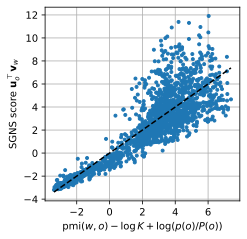

In [20]:
# The counts SGNS is shown: windows over the subsampled stream (they reach
# past the deleted words), and a window size drawn from 1..WINDOW, which
# averages the fixed-window counts; three subsampling draws
rng = np.random.default_rng(0)
kept = [ids[keep_mask(ids, counts, T_SUB, rng)] for _ in range(3)]
X_seen = (sum(d2l.cooccurrence_counts(k, V, b) for k in kept
              for b in range(1, WINDOW + 1)) / (len(kept) * WINDOW)).tocoo()
top = np.argsort(-X_seen.data)[:2000]  # the most frequent (w, o) pairs
w, o = X_seen.row[top], X_seen.col[top]
n_word = np.asarray(X_seen.sum(1)).ravel()
n_ctx, N = np.asarray(X_seen.sum(0)).ravel(), X_seen.sum()
P = counts ** ALPHA / (counts ** ALPHA).sum()  # the noise of training
pmi_top = np.log(X_seen.data[top] * N / (n_word[w] * n_ctx[o]))
target = pmi_top - np.log(K) + np.log(n_ctx[o] / N / P[o])
score = (sgns_v[w] * sgns_u[o]).sum(1).numpy()
print(f'Pearson r = {np.corrcoef(target, score)[0, 1]:.2f} over {len(top)} '
      f'pairs; mean score - target {np.mean(score - target):+.2f}')
lim = [target.min(), target.max()]  # the diagonal, over the targets
d2l.plot([target, lim], [score, lim],
         r'$\mathrm{pmi}(w, o) - \log K + \log(p(o) / P(o))$',
         r'SGNS score $\mathbf{u}_o^\top \mathbf{v}_w$', fmts=('.', 'k--'),
         figsize=(3.5, 3.5))

<!-- d2l:prose id=word-embeddings-md-18 fw=all -->

The points follow the line with a Pearson correlation of about 0.9 and no
offset to speak of. The cloud is narrow where the target is negative and
spreads widely among the strongly associated pairs: most of them score
below the line, and a plume overshoots it. "Skip-gram is PMI
factorization" is a statement about an optimum; a model trained for five
epochs is near it for frequent pairs, not at it.

## Evaluating Word Vectors

We have three tables from one slice: SGNS, SVD-PPMI and GloVe. Which is
best? @Levy.Goldberg.Dagan.2015 argued that the answer depends less on
the method than it seems: settings such as the noise exponent, which one
method's recipe fixed and another's left out, move the results as much as
the choice of method. We test this on our slice.

### Methods and Settings

Does any setting move $\rho$ as much as the choice of method? To find
out, the 23 stored runs vary both: SGNS with noise exponents $\alpha \in
\{0, 0.75, 1\}$, with and without subsampling, in three seeds each;
GloVe in three seeds; and SVD-PPMI, which needs no seed, with context
exponents 1 and 0.75. The cell prints $\rho$ of seed 0 with its interval
and the range over the seeds. As a live check, its last line sets the
stored default run of SGNS beside the one we trained above.

In [21]:
def grid_row(method, E, seconds, **settings):
    """One run of the grid: its settings, rho and interval per rating set,
    and the cosines of the covered pairs (for paired comparisons)."""
    row = dict(method=method, seconds=round(seconds, 1), **settings)
    for name, p in SETS.items():
        r = d2l.spearman_eval(E, vocab, p)
        row[name] = dict(rho=r.rho, ci=r.ci, n=r.n_covered,
                         cosines=np.round(r.cosines, 6).tolist())
    return row

def write_json(path, records):
    with open(path, 'w') as f:
        json.dump(records, f)

ALPHAS = (0.0, 0.75, 1.0)  # SGNS noise exponents; SVD-PPMI takes 1 and ALPHA
CONFIG = json.loads(json.dumps(dict(  # everything the grid's numbers rest on
    corpus=hashlib.sha1(ids.astype(np.int64).tobytes()).hexdigest(), V=V,
    window=WINDOW, dim=DIM, K=K, t_sub=T_SUB, alpha=ALPHA, alphas=ALPHAS,
    epochs=EPOCHS, batch=BATCH, lr=LR, seeds=SEEDS, glove=GLOVE,
    sets={name: dict(sha1=d2l.DATA_HUB[SOURCES[name]][1], n=covered[name])
          for name in SETS})))

if 'we-grid' in RERUN:
    rows = []
    for seed in SEEDS:
        for alpha in ALPHAS:
            for sub in (True, False):
                tic = time.time()
                E, _ = train_sgns(ids, counts, alpha, sub, seed, verbose=False)
                rows.append(grid_row('SGNS', E, time.time() - tic,
                                     alpha=alpha, subsample=sub, seed=seed))
        tic = time.time()
        E = train_glove(X, **GLOVE, seed=seed, verbose=False)
        rows.append(grid_row('GloVe', E, time.time() - tic, alpha=None,
                             subsample=False, seed=seed))
    for alpha in (1.0, ALPHA):  # deterministic: one run each
        tic = time.time()
        E = svd_embed(d2l.ppmi(X, alpha=alpha), DIM)
        rows.append(grid_row('SVD-PPMI', E, time.time() - tic, alpha=alpha,
                             subsample=False, seed=0))
    d2l.lm_save_rerun(ARTIFACTS['we-grid'][1], lambda path: write_json(
        path, dict(config=CONFIG, runs=rows)))
key, file = ARTIFACTS['we-grid']
with open(d2l.lm_artifact(key, file if 'we-grid' in RERUN else None)) as f:
    grid = json.load(f)
assert grid['config'] == CONFIG, 'the grid was made with other settings'
grid = grid['runs']

def setting(r):
    return r['method'] + ('' if r['method'] == 'GloVe' else
                          f", alpha={r['alpha']:g}") + (
        ', subsampled' if r['subsample'] else '')

def runs(method, **settings):  # the grid's runs of one setting, by seed
    return sorted((r for r in grid if r['method'] == method and all(
        r[k] == v for k, v in settings.items())), key=lambda r: r['seed'])

summary = {}
for r in grid:
    if r['seed'] == 0:
        same = runs(r['method'], alpha=r['alpha'], subsample=r['subsample'])
        summary[setting(r)] = {}
        for name in SETS:
            rho = [s[name]['rho'] for s in same]
            summary[setting(r)][name] = (
                f"{r[name]['rho']:.3f} [{r[name]['ci'][0]:.2f}, "
                f"{r[name]['ci'][1]:.2f}]"
                + (f'; seeds [{min(rho):.3f}, {max(rho):.3f}]'
                   if len(same) > 1 else ''))
for name in SETS:  # one table per benchmark: the page's width
    print(pd.DataFrame(summary).T[[name]].to_string())
default = runs('SGNS', alpha=ALPHA, subsample=True)[0]
live = {name: d2l.spearman_eval(sgns_v, vocab, p, n_boot=0).rho
        for name, p in SETS.items()}
# The same on the device that made the grid; another device draws other
# random numbers, so the two then differ by a few hundredths
print('this run vs the grid (SGNS defaults, seed 0): ' + '; '.join(
    f"{n} {live[n]:.3f} vs {default[n]['rho']:.3f}" for n in SETS))

                                                            WordSim353
SGNS, alpha=0, subsampled     0.528 [0.44, 0.61]; seeds [0.526, 0.537]
SGNS, alpha=0                 0.516 [0.42, 0.60]; seeds [0.516, 0.537]
SGNS, alpha=0.75, subsampled  0.562 [0.48, 0.64]; seeds [0.551, 0.562]
SGNS, alpha=0.75              0.536 [0.45, 0.62]; seeds [0.515, 0.570]
SGNS, alpha=1, subsampled     0.527 [0.44, 0.61]; seeds [0.521, 0.533]
SGNS, alpha=1                 0.540 [0.45, 0.62]; seeds [0.518, 0.550]
GloVe                         0.289 [0.18, 0.40]; seeds [0.265, 0.289]
SVD-PPMI, alpha=1                                   0.585 [0.50, 0.66]
SVD-PPMI, alpha=0.75                                0.574 [0.48, 0.65]
                                                            SimLex-999
SGNS, alpha=0, subsampled     0.205 [0.14, 0.27]; seeds [0.198, 0.205]
SGNS, alpha=0                 0.193 [0.12, 0.26]; seeds [0.190, 0.212]
SGNS, alpha=0.75, subsampled  0.182 [0.11, 0.25]; seeds [0.182, 0.191]
SGNS, 

<!-- d2l:prose id=word-embeddings-md-19 fw=all -->

On WordSim353 the nine rows fall into two groups: every setting of SGNS
and of SVD-PPMI lies between 0.52 and 0.59, and GloVe sits alone at 0.29.
On SimLex-999 all runs lie between 0.13 and 0.21. Even GloVe's lower
interval ends, 0.18 and 0.08, clear the random floor. The plot shows each
method at its default settings on the left, with the interval of seed 0
and each seed as a cross. The right panel zooms in on skip-gram. It shows
how far $\rho$ moves when the noise exponent changes, measured from the
default run, $\alpha = 0.75$ with subsampling, whose mean over the seeds
sits on the dashed zero line. Solid lines keep subsampling and dashed
lines drop it; each line is a mean over the three seeds, and its band
spans them.

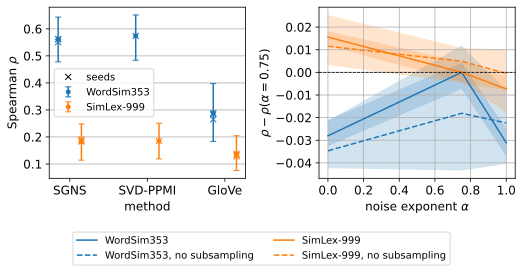

In [22]:
methods = {'SGNS': runs('SGNS', alpha=ALPHA, subsample=True),
           'SVD-PPMI': runs('SVD-PPMI', alpha=ALPHA), 'GloVe': runs('GloVe')}
series, seeds = {}, {}
for k, name in enumerate(SETS):  # seed 0 and its interval; all seeds
    first = [rs[0][name] for rs in methods.values()]
    series[name] = ([d['rho'] for d in first], [d['ci'][0] for d in first],
                    [d['ci'][1] for d in first])
    xs, ys = zip(*[(i + 0.15 * (2 * k - 1), r[name]['rho'])
                   for i, rs in enumerate(methods.values()) for r in rs])
    seeds[name] = (xs, ys)
with d2l.plt.rc_context({'font.size': 12}):  # legible on a slide
    fig, axes = d2l.plt.subplots(1, 2, figsize=(7.5, 3.8))
    d2l.plot_intervals(list(methods), series, 'method', r'Spearman $\rho$',
                       axes=axes[0], marks={'seeds': ('x', seeds)})
    bands, styles = {}, []
    for k, name in enumerate(SETS):  # mean over seeds; the band spans them;
        # each set's rho less that of the setting used, at 0 on the plot
        for sub in (True, False):
            rho = np.array([[r[name]['rho'] for r in runs(
                'SGNS', alpha=a, subsample=sub)] for a in ALPHAS]) - np.mean(
                    [r[name]['rho'] for r in runs('SGNS', alpha=ALPHA,
                                                  subsample=True)])
            bands[f"{name}{'' if sub else ', no subsampling'}"] = (
                rho.mean(1), rho.min(1), rho.max(1))
            styles.append((f'C{k}', '-' if sub else '--'))
    d2l.plot_intervals(ALPHAS, bands, r'noise exponent $\alpha$',
                       rf'$\rho - \rho(\alpha = {ALPHA})$', kind='band',
                       reference=0.0, axes=axes[1])
    for line, band, (color, style) in zip(axes[1].lines, axes[1].collections,
                                          styles):  # hue: rating set, as left
        line.set(color=color, linestyle=style)
        band.set_color(color)
    axes[0].legend(fontsize='small')
    axes[1].get_legend().remove()  # below the figure: the bands fill it
    fig.legend(*axes[1].get_legend_handles_labels(), loc='lower center',
               ncol=2, fontsize='small')
    d2l.plt.tight_layout(rect=(0, 0.15, 1, 1))

<!-- d2l:prose id=word-embeddings-md-20 fw=all -->

Is SGNS better than SVD-PPMI? On the left their intervals overlap almost
entirely, and yet that does not settle it, because unpaired intervals
overstate the uncertainty of a difference. Both tables are scored on the
same pairs, and a pair that is hard for one tends to be hard for the
other. As in that section, we therefore compare them on
the same items. A rank correlation is not a mean of per-item scores, so
the next cell resamples the pairs and recomputes both correlations on
each resample. The seed range says how much a difference moves from run
to run.

In [23]:
def rank_corr(a, b):  # Spearman along the last axis, as in spearman_eval
    from scipy.stats import rankdata
    a, b = rankdata(a, axis=-1), rankdata(b, axis=-1)
    a, b = a - a.mean(-1, keepdims=True), b - b.mean(-1, keepdims=True)
    return (a * b).sum(-1) / np.sqrt((a * a).sum(-1) * (b * b).sum(-1))

sgns = runs('SGNS', alpha=ALPHA, subsample=True)
COMPARE = {  # name: (kind, runs A, runs B); a single run pairs every seed
    'SGNS - SVD-PPMI': ('method', sgns, runs('SVD-PPMI', alpha=ALPHA)),
    'SGNS - GloVe': ('method', sgns, runs('GloVe')),
    'SVD-PPMI - GloVe': ('method', runs('SVD-PPMI', alpha=ALPHA),
                         runs('GloVe')),
    'alpha 0.75 - 0': ('setting', sgns, runs('SGNS', alpha=0.0,
                                             subsample=True)),
    'alpha 1 - 0.75': ('setting', runs('SGNS', alpha=1.0, subsample=True),
                       sgns),
    'SVD alpha 0.75 - 1': ('setting', runs('SVD-PPMI', alpha=ALPHA),
                           runs('SVD-PPMI', alpha=1.0)),
    'subsampling on - off': ('setting', sgns, runs('SGNS', alpha=ALPHA,
                                                   subsample=False))}
rows = []
for label, (kind, A, B) in COMPARE.items():
    n = max(len(A), len(B))  # 3 seeds, or 1 (SVD) repeated
    pairs_ab = list(zip(A * (n // len(A)), B * (n // len(B))))
    for name, p in SETS.items():
        idx = vocab.token_to_idx
        human = p[[w1 in idx and w2 in idx for w1, w2 in
                   zip(p.word1, p.word2)]].score.to_numpy()
        a, b = (np.array(r[name]['cosines']) for r in (A[0], B[0]))
        assert len(a) == len(b) == len(human)  # the same pairs, in order
        boot = np.random.default_rng(0).integers(0, len(human),
                                                 (2000, len(human)))
        diff = rank_corr(a[boot], human[boot]) - rank_corr(b[boot],
                                                           human[boot])
        by_seed = [x[name]['rho'] - y[name]['rho'] for x, y in pairs_ab]
        rows.append(dict(comparison=label, kind=kind, set=name,
                         delta=rank_corr(a, human) - rank_corr(b, human),
                         ci_lo=np.quantile(diff, 0.025),
                         ci_hi=np.quantile(diff, 0.975),
                         seed_lo=min(by_seed), seed_hi=max(by_seed)))
deltas = pd.DataFrame(rows)
print(deltas.round(3).to_string(index=False))
for kind in ('method', 'setting'):
    d = deltas[deltas.kind == kind]
    big = d.loc[d.delta.abs().idxmax()]
    print(f'largest |delta rho| by {kind}: {abs(big.delta):.2f} '
          f'({big.comparison}, {big.set})')

          comparison    kind        set  delta  ci_lo  ci_hi  seed_lo  seed_hi
     SGNS - SVD-PPMI  method WordSim353 -0.012 -0.079  0.054   -0.023   -0.012
     SGNS - SVD-PPMI  method SimLex-999 -0.003 -0.044  0.035   -0.003    0.006
        SGNS - GloVe  method WordSim353  0.273  0.170  0.381    0.267    0.296
        SGNS - GloVe  method SimLex-999  0.045 -0.022  0.109    0.045    0.058
    SVD-PPMI - GloVe  method WordSim353  0.285  0.183  0.383    0.285    0.309
    SVD-PPMI - GloVe  method SimLex-999  0.048 -0.011  0.105    0.048    0.057
      alpha 0.75 - 0 setting WordSim353  0.035  0.003  0.067    0.014    0.036
      alpha 0.75 - 0 setting SimLex-999 -0.022 -0.046  0.001   -0.022   -0.012
      alpha 1 - 0.75 setting WordSim353 -0.035 -0.058 -0.013   -0.040   -0.018
      alpha 1 - 0.75 setting SimLex-999  0.002 -0.017  0.021   -0.023    0.002
  SVD alpha 0.75 - 1 setting WordSim353 -0.011 -0.029  0.007   -0.011   -0.011
  SVD alpha 0.75 - 1 setting SimLex-999  0.004 -0.01

<!-- d2l:prose id=word-embeddings-md-21 fw=all -->

The two factorizations of PMI cannot be told apart. SGNS and SVD-PPMI
differ by 0.01 on WordSim353 and by less on SimLex-999, with intervals
that straddle zero. This is what the equation leads us to
expect of two factorizations of closely related matrices.

The 0.75 power helps skip-gram on WordSim353, a little. On the right of
the plot the WordSim353 line peaks at 0.75 and drops by about three
hundredths toward either end. In the table, 0.75 beats noise by frequency
by two to four hundredths in every seed, with an interval that excludes
zero, and beats uniform noise by a similar amount, at the edge of
detection. On SimLex-999 it does not help: that line slopes gently
downward from $\alpha = 0$, and uniform noise is ahead by one to two
hundredths in every seed, again at the edge of detection. Subsampling
changes $\rho$ by an amount whose sign flips between seeds, too little
for three seeds to show. On this slice its benefit is speed: an epoch
has half as many centers.

The large gap is GloVe's alone. Both factorizations exceed it by about
0.3 on WordSim353, in every seed. On SimLex-999, where all three methods
score low, the gap is 0.05 and its interval includes zero. The claim we
set out to test therefore holds between the two methods that factorize
PMI: no difference of method is detectable there, while one setting, the
noise exponent, has a detectable effect. For GloVe it fails.

Why does GloVe trail? Its loss never sees a pair that does not occur, and
on three million words that is 98% of the pairs. Nothing in the loss
pushes down the score of a word with a context it never meets, and a rare
word, with few nonzero counts, is held in place by few terms at all. The
next cell splits the covered pairs of each rating set at the median count
of their rarer word and scores the seed-0 tables on each half.

In [24]:
idx, rows = vocab.token_to_idx, {}
for name, p in SETS.items():
    p = p[[w1 in idx and w2 in idx for w1, w2 in zip(p.word1, p.word2)]]
    rarer = np.minimum(*(counts[[idx[w] for w in col]]
                         for col in (p.word1, p.word2)))
    rare = rarer < np.median(rarer)  # the pairs of rarer words
    for method, rs in methods.items():  # seed 0 of the grid-plot settings
        cos = np.array(rs[0][name]['cosines'])
        for half, m in (('rare half', rare), ('frequent half', ~rare)):
            rows.setdefault((name, half), {})[method] = rank_corr(
                cos[m], p.score.to_numpy()[m])
print('Spearman rho on each half of the covered pairs, split at the median '
      'count of the rarer word')
print(pd.DataFrame(rows).round(2).to_string())

Spearman rho on each half of the covered pairs, split at the median count of the rarer word
         WordSim353               SimLex-999              
          rare half frequent half  rare half frequent half
SGNS           0.53          0.61       0.15          0.21
SVD-PPMI       0.54          0.61       0.18          0.21
GloVe          0.21          0.40       0.11          0.20


<!-- d2l:prose id=word-embeddings-md-22 fw=all -->

On WordSim353 GloVe trails in both halves: 0.21 against 0.53 and 0.54
on the pairs of rarer words, 0.40 against 0.61 on the frequent ones. The
gap is wider among rare words, about 0.3 against 0.2, in the direction
the second part of the argument predicts, although with half of the
pairs on each side that difference is rough. What matters more is that a
gap remains among frequent words. Rarity is not the whole story: the
pairs that never enter the loss cost GloVe on frequent words too. On
SimLex-999, where every method scores low, the halves differ by a few
hundredths.

It is not the optimizer. In runs not shown here, more passes, smaller
minibatches, other learning rates and the paper's distance-weighted
counts all left GloVe far behind the other two methods. More text narrows
the gap, and Exercise 6 measures by how
much. Swivel [@Shazeer.Doherty.Evans.ea.2016] was designed against
this weakness: its loss gives the pairs that never occur a term of their
own. Our measurement concerns three million words, and GloVe was built
for billions. Its released vectors, trained on six billion tokens, are
the ones we use for the last two tests of this section.

For a corpus of your own, SVD-PPMI is a good first choice. It is
deterministic, takes seconds and matched SGNS on both sets, and its
context exponent made no detectable difference. SGNS streams over the
text and scales to corpora whose count matrix would not fit in memory;
with SGNS, use the 0.75 power.

### Nearest Neighbors

A correlation summarizes a thousand pairs. The nearest neighbors of a
word, the rows with the largest cosine to its row, show what a table
learned about one word.

In [25]:

def nearest_neighbors(E, vocab, word, k=5, exclude_self=True):
    """The k rows of E nearest to word's row in cosine, as a list of
    (token, cosine). vocab is a d2l.Vocab or a TokenEmbedding (whose
    unknown token at index 0 is never returned), or a Hugging Face
    tokenizer, for which word must be a single token."""
    if hasattr(vocab, 'token_to_idx'):
        i, skip = vocab.token_to_idx[word], [0]
        name = lambda j: vocab.idx_to_token[j]
    else:
        ids = vocab.encode(word, add_special_tokens=False)
        if len(ids) != 1:
            raise ValueError(f'{word!r} is {len(ids)} tokens, not one')
        i, skip, name = ids[0], [], lambda j: vocab.decode([j])
    Z = F.normalize(torch.as_tensor(E)[:len(vocab)].float(), dim=1)
    cos = Z @ Z[i]
    cos[skip + ([i] if exclude_self else [])] = -math.inf
    top = torch.topk(cos, k)
    return [(name(int(j)), float(c)) for c, j in zip(top.values, top.indices)]

<!-- d2l:prose id=word-embeddings-md-23 fw=all -->

Does *doctor* land next to *physician*, as the opening hoped?

In [26]:
tables = {'SGNS': sgns_v, 'SVD-PPMI': svd_vecs, 'GloVe': glove_vecs}
n_of = lambda w: f'{w} ({counts[vocab.token_to_idx[w]]:,} times)'
for w in ('doctor', 'chip', 'stock', 'bank'):  # a line per method
    print(n_of(w) + ''.join(f'\n  {m:9s} ' + ', '.join(
        t for t, _ in d2l.nearest_neighbors(E, vocab, w))
        for m, E in tables.items()))
print('on the slice: ' + n_of('physician'))

doctor (205 times)
  SGNS      vincent, amy, torchwood, tardis, utterson
  SVD-PPMI  scully, skinner, mulder, jackman, amy
  GloVe     sailor, vincent, snowy, patient, comedian
chip (30 times)
  SGNS      breakfast, trailer, monthly, trucks, toy
  SVD-PPMI  yamaha, publishing, publishers, monthly, halo
  GloVe     jetport, kitkehahkis, timing, transaction, recapture
stock (74 times)
  SGNS      enterprises, purchasing, financing, bankrupt, profits
  SVD-PPMI  pictures, shops, paramount, share, goldwyn
  GloVe     footage, sarajevo, melody, lifted, revenues
bank (452 times)
  SGNS      ubs, winterthur, asset, swiss, banks
  SVD-PPMI  ubs, winterthur, merger, suisse, banks
  GloVe     swiss, switzerland, corporation, ubs, merger
on the slice: physician (38 times)


<!-- d2l:prose id=word-embeddings-md-24 fw=all -->

It does not. *Physician* occurs only 38 times on the slice, against 205
for *doctor*, and a *doctor* there is mostly the Doctor of *Doctor
Who* (Amy, Torchwood, the TARDIS) or a character in *The X-Files*
(Scully, Mulder, Skinner). *Chip*, with 30 occurrences and many senses,
gets lists that look like noise for every method. *Stock* shows
something more interesting. Under SGNS its neighbors come from finance
(*enterprises*, *financing*, *bankrupt*, *profits*), under SVD-PPMI
mostly from Hollywood (*pictures*, *paramount*, *goldwyn*): one word,
two senses, and the method decides which one wins its row. *Bank* sits among Swiss banks for
all three methods. GloVe's lists are the noisiest overall, in line with
its correlations. Nearest neighbors describe the corpus, not the
language, and the articles of this slice include a good deal of
television.

### Analogies

Two more tests of word vectors are famous, and both are best read as
cautionary tales about evaluation. The first is the analogy: *king* $-$
*man* $+$ *woman* lies close to *queen*. Such tests are usually run on
vectors trained on billions of words, so we load the pretrained GloVe-6B
vectors, which GloVe's authors trained on six billion tokens of Wikipedia
and newswire.

In [27]:

class TokenEmbedding:
    """Token Embedding."""
    def __init__(self, embedding_name):
        self.idx_to_token, self.idx_to_vec = self._load_embedding(
            embedding_name)
        self.unknown_idx = 0
        self.token_to_idx = {token: idx for idx, token in
                             enumerate(self.idx_to_token)}

    def _load_embedding(self, embedding_name):
        idx_to_token, idx_to_vec = ['<unk>'], []
        data_dir = d2l.download_extract(embedding_name)
        # GloVe website: https://nlp.stanford.edu/projects/glove/
        # fastText website: https://fasttext.cc/
        with open(os.path.join(data_dir, 'vec.txt'), 'r') as f:
            for line in f:
                elems = line.rstrip().split(' ')
                token, elems = elems[0], [float(elem) for elem in elems[1:]]
                # Skip header information, such as the top row in fastText
                if len(elems) > 1:
                    idx_to_token.append(token)
                    idx_to_vec.append(elems)
        idx_to_vec = [[0] * len(idx_to_vec[0])] + idx_to_vec
        return idx_to_token, d2l.tensor(idx_to_vec)

    def __getitem__(self, tokens):
        indices = [self.token_to_idx.get(token, self.unknown_idx)
                   for token in tokens]
        vecs = self.idx_to_vec[d2l.tensor(indices)]
        return vecs

    def __len__(self):
        return len(self.idx_to_token)

<!-- d2l:prose id=word-embeddings-md-25 fw=all -->

For an analogy $a : b :: c : x$, the method called 3CosAdd answers with the
word $x$ whose unit vector has the largest cosine with $\mathbf{b} -
\mathbf{a} + \mathbf{c}$, all three normalized. If the offset $\mathbf{b}
- \mathbf{a}$ is small compared with $\mathbf{c}$, the nearest word is $c$
itself, so the standard evaluation excludes the query words from the
answers. We run five analogies with and without that exclusion.

In [28]:
check_sha1(d2l.download('glove.6b.100d'), 'glove.6b.100d')
glove6b = d2l.TokenEmbedding('glove.6b.100d')
Z6b = F.normalize(glove6b.idx_to_vec.float(), dim=1)

def analogy(a, b, c, exclude=True):
    """3CosAdd: the word x maximizing cos(x, b - a + c), for a : b :: c : x."""
    i = [glove6b.token_to_idx[w] for w in (a, b, c)]
    scores = Z6b @ (Z6b[i[1]] - Z6b[i[0]] + Z6b[i[2]])
    scores[[0] + (i if exclude else [])] = -math.inf  # 0 is <unk>
    return glove6b.idx_to_token[int(scores.argmax())]

QUERIES = [('man', 'woman', 'king'), ('paris', 'france', 'tokyo'),
           ('bad', 'worst', 'big'), ('walk', 'walked', 'go'),
           ('do', 'did', 'see')]
n_input = 0
for a, b, c in QUERIES:
    x, y = analogy(a, b, c), analogy(a, b, c, exclude=False)
    n_input += y in (a, b, c)
    print(f'{a}:{b} :: {c}:?  excluded -> {x:<8} not excluded -> {y}')
print(f'{n_input} of {len(QUERIES)} answers are a query word when the '
      'query words are not excluded')

man:woman :: king:?  excluded -> queen    not excluded -> king
paris:france :: tokyo:?  excluded -> japan    not excluded -> japan
bad:worst :: big:?  excluded -> biggest  not excluded -> biggest
walk:walked :: go:?  excluded -> went     not excluded -> went
do:did :: see:?  excluded -> saw      not excluded -> see
2 of 5 answers are a query word when the query words are not excluded


<!-- d2l:prose id=word-embeddings-md-26 fw=all -->

With the query words excluded, all five answers are right: *queen*,
*japan*, *biggest*, *went* and *saw*. Without the exclusion, two of the
five answers are a query word: *king* for *man* : *woman* :: *king*, and
*see* for *do* : *did* :: *see*. The famous analogy holds because the
method forbids the answer *king*, as @Linzen.2016 pointed out. An
analogy accuracy means little unless it says whether the inputs were
excluded.

### Bias

Word vectors record the associations of their text, stereotypes included
[@Bolukbasi.Chang.Zou.ea.2016]. The second test probes for them with
a direction: the unit vector $\mathbf{g}$ along $\mathbf{he} -
\mathbf{she}$, and the projection of each word's unit vector onto it. A
simplified version of the repair that Bolukbasi et al. proposed removes
the projection onto $\mathbf{g}$ from every word, so that no word leans
either way.

@Gonen.Goldberg.2019 argued that this hides the bias rather than
removing it, and we can test the argument. After the removal, we find each
profession's ten nearest neighbors and average their *original*
projections. If the removal had erased the association, the new neighbors
of a profession would lean toward *she* or *he* no more than chance
allows. If it only hid it, their lean would still follow the profession's
own original lean.

In [29]:
PROFESSIONS = ['nurse', 'receptionist', 'librarian', 'housekeeper',
               'hairdresser', 'nanny', 'secretary', 'homemaker', 'dancer',
               'teacher', 'engineer', 'carpenter', 'mechanic', 'architect',
               'programmer', 'surgeon', 'captain', 'philosopher',
               'scientist', 'manager']
g = F.normalize(Z6b[glove6b.token_to_idx['he']]
                - Z6b[glove6b.token_to_idx['she']], dim=0)
Z_hidden = F.normalize(Z6b - (Z6b @ g)[:, None] * g, dim=1)  # all words
lean = Z6b @ g  # every word's original projection on he - she
rows = []
for w in PROFESSIONS:
    near = [[glove6b.token_to_idx[t] for t, _ in
             d2l.nearest_neighbors(Z, glove6b, w, k=10)]
            for Z in (Z6b, Z_hidden)]
    i = glove6b.token_to_idx[w]
    rows.append(dict(word=w, before=float(lean[i]),
                     after=float(Z_hidden[i] @ g),
                     overlap=len(set(near[0]) & set(near[1])),
                     # the original lean of its neighbors after removal
                     neighbors=float(lean[near[1]].mean())))
bias = pd.DataFrame(rows).sort_values('before')
print(bias.round(3).to_string(index=False))
assert bias.after.abs().max() < 1e-6  # zero by construction
print(f'median overlap of the top 10 neighbors: '
      f'{bias.overlap.median():.0f} of 10\ncorrelation of a profession\'s '
      f'original projection with its neighbors\' after removal: '
      f'{np.corrcoef(bias.before, bias.neighbors)[0, 1]:.2f}')

        word  before  after  overlap  neighbors
   homemaker  -0.367    0.0        5     -0.108
 housekeeper  -0.321   -0.0        7     -0.237
      dancer  -0.295   -0.0        9     -0.191
       nurse  -0.278   -0.0        9     -0.063
 hairdresser  -0.270   -0.0        6     -0.092
receptionist  -0.268   -0.0        9     -0.145
       nanny  -0.255   -0.0        7     -0.235
   librarian  -0.100    0.0        9      0.047
     teacher  -0.070    0.0        9      0.030
     surgeon   0.014    0.0        9     -0.046
   carpenter   0.018    0.0        9      0.020
  programmer   0.062    0.0       10      0.049
   scientist   0.082   -0.0       10      0.051
    mechanic   0.118    0.0        9      0.025
    engineer   0.162    0.0        9      0.103
 philosopher   0.172   -0.0        9      0.097
   secretary   0.182   -0.0        9      0.196
   architect   0.193    0.0        9      0.045
     captain   0.210   -0.0        8      0.104
     manager   0.284    0.0        8    

<!-- d2l:prose id=word-embeddings-md-27 fw=all -->

Before the removal, *homemaker* ($-0.37$) and *nurse* ($-0.28$) lean
toward *she*, and *manager* ($+0.28$) and *captain* ($+0.21$) toward
*he*. These numbers describe how the corpus of GloVe-6B uses the words:
*secretary* leans toward *he* ($+0.18$), probably because in newswire a
secretary is often a Secretary of State. After the removal every
projection is zero by construction, and the neighborhoods barely change.
The median profession keeps 9 of its 10 nearest neighbors, and the new
neighbors still lean the way the word did, with a correlation of about
0.9 over the 20 professions. The association is spread over many
directions, and removing one of them hides it from one probe.

## Static Vectors and a Language Model's Table

We return to the table that opened the section. Qwen3-0.6B
[@Yang.Li.Yang.ea.2025], loaded with `d2l.load_qwen3` as in
that section, has a token table of 151,936 rows of
width 1,024 among its 596 million parameters. The cell computes the
table's share of the model and the nearest neighbors of four words. For
the opening question it prints the cosine of *doctor* and *physician*,
with the rank of *physician* among the neighbors of *doctor*.

In [30]:
QWEN = 'Qwen/Qwen3-0.6B'
model = d2l.load_qwen3(QWEN, device=device)
tok = transformers.AutoTokenizer.from_pretrained(QWEN,
                                                 revision=model.revision)
table = model.token_emb.weight.detach().float()
n_params = sum(p.numel() for p in model.parameters())
_, _, files = d2l._qwen3_files(QWEN, model.revision)
n_file = 0
for path in files:  # what the checkpoint stores, from the file headers
    with safe_open(path, 'pt') as f:
        n_file += sum(math.prod(f.get_slice(k).get_shape()) for k in f.keys())
print(f'table {tuple(table.shape)}: {table.numel():,} of {n_params:,} '
      f'parameters ({table.numel() / n_params:.1%})\n  the checkpoint file '
      f'holds {n_file:,} numbers')
tied = (model.hf_config['tie_word_embeddings']
        and not hasattr(model, 'lm_head'))
print(f'tied: {tied}; the output layer multiplies by the same table')
assert tied and abs(table.numel() / n_params - 0.261) < 5e-4
words = ['doctor', 'bank', 'river', 'money']
near = lambda E, v, w: ', '.join(repr(t) for t, _ in
                                 d2l.nearest_neighbors(E, v, w))
for w in words:  # a line per table
    print(f'{w}\n  Qwen3-0.6B table   {near(table, tok, " " + w)}\n'
          f'  SGNS (this slice)  {near(sgns_v, vocab, w)}')
index = {'SGNS': (sgns_v, vocab.token_to_idx),
         'GloVe-6B': (Z6b, glove6b.token_to_idx),
         'Qwen3 table': (table, {w: tok.encode(' ' + w)[0] for w in words})}
for o in ('river', 'money'):  # one vector for both senses of "bank"
    print(f'cos(bank, {o}): ' + ', '.join(
        f'{m} {F.cosine_similarity(E[ix["bank"]], E[ix[o]], dim=0):.2f}'
        for m, (E, ix) in index.items()))
index['Qwen3 table'][1]['physician'], = tok.encode(' physician')  # one token
for m, (E, ix) in index.items():  # the opening's question, in numbers
    Z = F.normalize(E[:len(tok) if m == 'Qwen3 table' else None].float(),
                    dim=1)  # the table's rows for real tokens
    c = Z @ Z[ix['doctor']]
    c[[ix['doctor']] + ([0] if m != 'Qwen3 table' else [])] = -math.inf
    p = c[ix['physician']]  # index 0 of the word tables is <unk>
    print(f'{m:12s} cos(doctor, physician) {p:.2f}; physician is neighbor '
          f'{int((c > p).sum()) + 1:,} of {int(c.isfinite().sum()):,}')
del model, table
d2l.lm_free()
print(f'notebook: {time.time() - TIC:.0f} s')

table (151936, 1024): 155,582,464 of 596,049,920 parameters (26.1%)
  the checkpoint file holds 751,632,384 numbers
tied: True; the output layer multiplies by the same table
doctor
  Qwen3-0.6B table   ' doctors', ' Doctor', '医生', 'Doctor', 'doctor'
  SGNS (this slice)  'vincent', 'amy', 'torchwood', 'tardis', 'utterson'
bank
  Qwen3-0.6B table   ' Bank', 'bank', 'Bank', '银行', '_bank'
  SGNS (this slice)  'ubs', 'winterthur', 'asset', 'swiss', 'banks'
river
  Qwen3-0.6B table   ' River', ' rivers', 'River', '河流', '河'
  SGNS (this slice)  'missouri', 'upstream', 'confluence', 'headwaters', 'tributaries'
money
  Qwen3-0.6B table   ' Money', 'money', 'Money', '_money', ' MONEY'
  SGNS (this slice)  'guaranteed', 'monetary', 'pay', 'rents', 'raise'
cos(bank, river): SGNS 0.53, GloVe-6B 0.33, Qwen3 table 0.24
cos(bank, money): SGNS 0.32, GloVe-6B 0.57, Qwen3 table 0.22
SGNS         cos(doctor, physician) 0.44; physician is neighbor 977 of 17,995
GloVe-6B     cos(doctor, physician) 0.77; phy

notebook: 94 s


<!-- d2l:prose id=word-embeddings-md-28 fw=all -->

The table holds 156 million of the 596 million parameters, or 26%: a
quarter of the model is a lookup table. It is tied, so the output layer
multiplies by the same matrix. The checkpoint file stores the table once
for each use, so it holds more numbers than the model has parameters,
and a count taken from the file overstates the size of the model.

The neighbors in Qwen's table are of a different kind from those of
SGNS. *Doctor* sits next to *doctors*, *Doctor*, the Chinese word for
doctor, and itself without the leading space, and the other three words
likewise sit among their spellings and translations. The table has two
jobs. It hands the token to the layers above, which work out its meaning
from the context. Because it is tied, it also scores the token as the
next one, and *doctor* and *Doctor* are predicted in the same places, so
their rows end up close.

Now we can answer the question we started with. In the GloVe-6B vectors,
trained on six billion tokens, *physician* is the nearest row to *doctor*,
at a cosine of 0.77. In Qwen's table it comes sixth (0.65), right behind
the spellings and the translation of *doctor* itself. On our slice of
three million words SGNS puts it 977th of about 18,000, at 0.44:
*physician* is rare there, and *doctor* keeps the company of *Doctor
Who*. Training does put synonyms next to each other, given enough text in
which they keep the same company.

Nothing in such a table requires the categories to be words. Any
categorical variable with many values can have one: store numbers,
product codes, postal codes or user ids. @Guo.Berkhahn.2016
trained such *entity embeddings* with a network that predicts from
tabular data, and categories that behave alike ended up with nearby
rows, as words with similar company do. For a store, one row per value
is what we want, since a store is the same store wherever it appears.

A word is not. Under SGNS on our slice, *bank* is closer to *river*
(0.53) than to *money* (0.32), although its nearest neighbors are Swiss
banks. In GloVe-6B the order is reversed (0.33 and 0.57), and in Qwen's
table neither cosine is large (0.24 and 0.22). Each table places *bank* at
one point, and its corpus decides where that point lies between the bank
of a river and the bank that keeps our money. A vector computed from the
sentence around the word would not have to choose, and
that section computes one.

## Summary

A word vector records how often a word occurs near other words, compared
with how often it would by chance. At its optimum with free scores,
skip-gram with negative sampling scores a pair by its pointwise mutual
information minus $\log K$, plus an offset set by the noise distribution.
A toy corpus of four distinct words confirms this to the precision of
the optimizer, and a model trained on three million words of Wikipedia
follows it closely for frequent pairs. A truncated SVD of the positive PMI matrix
computes such a factorization in seconds and cannot be told from
skip-gram on human similarity ratings, while GloVe, whose loss skips the
pairs that never occur, trails on a corpus this small. Comparing word
vectors takes the covered pairs, a random floor and paired differences,
and analogy and bias tests need the same care about protocol. Every
static table, word2vec's or a language model's, gives a word one vector,
so *physician* can land next to *doctor*, given enough text, but *bank*
cannot have two meanings; vectors computed from context come next.

## Exercises

1. **Subsampling and the optimum.** Each occurrence of a word $w$ of
   relative frequency $f(w) > t$ is kept with probability $r_w =
   \sqrt{t/f(w)}$; rarer words have $r_w = 1$.
    1. Show that the expected number of kept occurrences of $w$ in a corpus
       of $N$ tokens is $N\sqrt{t f(w)}$. Subsampling thus replaces a
       frequency by the geometric mean of the frequency and $t$. What does
       it do to the ratio of the counts of two frequent words?
    1. Ignore that windows reach further after deletions, so that a pair
       survives with probability $r_w r_o$, and keep the noise distribution
       $P$ computed from the full counts, as the code does. Show that the
       free-score optimum on the subsampled text is
       $s^*(w, o) + \log r_o - \log \bar r_w$, where $\bar r_w = \sum_{o'}
       r_{o'} X_{wo'} / \sum_{o'} X_{wo'}$. Why does the keep rate of the
       center word cancel?
    1. Which scores does subsampling lower the most, and how does its
       effect compare with that of the noise exponent in
       the equation?
    1. A pair at distance 6 in the original text can enter the counts that
       skip-gram sees. Explain how, and say which pairs gain most from it.

1. [code] **The optimum for other numbers of noise words.** Rerun the toy
   check of that section with $K = 1$, 5 and 15.
    1. Before running, predict from the printed counts which optimal
       scores are positive for $K = 1$ with noise drawn by frequency, and
       why. Then check your prediction, and check that the optimum
       follows the equation for every $K$.
    1. The printed table of optimal scores for $\alpha = 0.75$ is not
       symmetric, although the counts are: *steam* and *gas* score
       $-0.86$ in one order and $-0.81$ in the other. Explain the two
       values from the offset in the equation.
    1. Delete the pair *steam*–*gas* from the counts, setting both of its
       entries to zero, and run the optimizer again. What happens to its
       score as the iterations proceed, and how do positive PMI and GloVe
       each avoid the problem?
    1. Back on the slice, compute SVD-PPMI with `shift=np.log(K)` for $K
       = 5$ and 15, the shift that the optimum of skip-gram contains.
       Compare $\rho$ with that of the unshifted SVD-PPMI on both rating
       sets, with paired intervals as in that section.
       Which entries of the matrix does the shift remove, and does
       removing them help?

1. [code] **Analogy accuracy and width.** ● Download the Google analogy set
   `questions-words.txt` (Apache-2.0) and train SGNS on the slice with
   `DIM` $\in \{25, 50, 100, 300\}$, three seeds each.
    1. Report the number of covered questions and the 3CosAdd accuracy with
       and without excluding the query words, with the seed range. At
       which width does the difference between the two protocols shrink?
    1. For the questions that fail only without the exclusion, which query
       word is returned? Relate the answer to the length of $\mathbf{b} -
       \mathbf{a}$ compared with that of $\mathbf{c}$.

1. [code] **Center table, context table, or their sum.** Evaluate
   $\mathbf{U}$, $\mathbf{V}$ and $\mathbf{V} + \mathbf{U}$ of the default
   run on both rating sets, with paired intervals for the differences
   computed as in that section.
    1. Which differences can you detect?
    1. Explain why the choice matters for skip-gram and does not arise for
       the tied table of Qwen3-0.6B.
    1. With $\mathbf{V} + \mathbf{U}$, the cosine of two words contains
       the terms $\mathbf{v}_w^\top \mathbf{u}_{w'}$. Use
       the equation to say what these terms measure.

1. [code] **CBOW.** The continuous bag of words, word2vec's other model
   [@Mikolov.Chen.Corrado.ea.2013], reverses the prediction: the mean
   of the context vectors of a window predicts the center word. Implement
   it with $K$ noise words per window, and train it with the same budget
   of epochs and the same noise distribution. Compare $\rho$ on both rating
   sets, with paired intervals against SGNS, and the seconds per epoch.
   Which updates does CBOW perform fewer of, and what does that predict
   for rare words?

1. [code] **GloVe and the size of the corpus.** ● The text of
   that section claims that GloVe's gap narrows with more
   text. Test it. For the first two parts, set `N_WORDS` to 30 million and
   skip the cells of the grid, whose stored results belong to the
   three-million-word slice.
    1. Measure the share of zero entries in the count matrix of the most
       frequent 18,000 words.
    1. Train GloVe with the same settings and compute SVD-PPMI on the
       larger slice, and compare their $\rho$ on WordSim353 with a paired
       interval. Does the gap shrink as the share of zeros falls?
    1. The text states that a better fit of GloVe's loss does not close
       the gap. Check one case: train GloVe once more on the
       three-million-word slice with ten times as many passes, and
       compare the loss and $\rho$ with those of the 50 passes.

1. [extended] **An embedding for a categorical column.** ●● Take the house
   prices of that section and one categorical column with
   many values, such as the neighborhood.
    1. Show that a table of width $d$ followed by a linear layer is a
       linear function of the one-hot vector of rank at most $d$. Under a
       linear model, when can it differ from one-hot features at all?
    1. Fit the linear model of that section with one-hot
       features and with tables of width $d \in \{2, 4, 32\}$, and then
       with a small MLP on top of each. Compare the $k$-fold validation
       errors of that section over three seeds.
    1. Plot the rows of the width-2 table, and say whether neighborhoods
       with similar prices lie close together.